### 도시 모빌리티 수요 예측: 공공자전거 대여량 분석 (회귀)
• 프로젝트 개요:날씨, 시간대, 요일 등의 데이터를 활용해 특정 시간대의 공공자전거 대여 수요를 예측하고, 도시 자원 배치를 최적화하는 방안을 고민해 봅니다.
• 학습 목표:
• 수치형 및 범주형 데이터의 전처리 및 인코딩 기법 체득
• 회귀 모델(LinearRegression, RandomForestRegressor) 적용 및 평가
• RMSE, MAE지표를 활용한 모델 성능 해석
수행 단계:
1. 데이터 탐색 (결측치 확인 및 시각화) ***# 해결***
2. 범주형 변수(날씨, 요일 등) 원-핫 인코딩 처리 ***# 해결***
3. 학습/테스트 데이터셋 분리 및 모델 학습
4. 예측 결과 시각화(실제값 vs 예측값 비교) 및 오차 분석
기대 산출물:시간대별 대여량 예측 모델 및 요인별 영향도 분석 리포트

- 컬럼 변수
  - 날짜 : date
  - 대여량 : Rent Bike Count
  - 시간 : Hour
  - 일사량 : Solar Radiation
  - 강수량 : Rainfall(mm)
  - 적설량 : Snowfall(cm)
  - 계절 : Seasons
  - 공휴일 : Holiday
  - 운영 여부 : Functioning Day

  - 회귀 모델
    - LinearRegression, RandomForestRegressor

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split


In [ ]:
bike_data = pd.read_csv("/content/drive/MyDrive/SeoulBikeData.csv", encoding='latin1')

selected_columns = [
    'Date',
    'Rented Bike Count',
    'Hour',
    'Solar Radiation (MJ/m2)',
    'Rainfall(mm)',
    'Snowfall (cm)',
    'Seasons',
    'Holiday',
    'Functioning Day'
]

# 선택한 컬럼만 추출
bike_data = bike_data[selected_columns].copy()


print("자전거 대여 데이터")
print(bike_data.head(10))

print("결측치 현황 탐색")
missing_counts = bike_data.isnull().sum()
print(missing_counts)

missing_raito = (missing_counts / len(bike_data)) * 100

print("컬럼별 결측지")
print(missing_counts[missing_counts > 0])

print("컬럼별 결측치 비율(%)")
print(missing_raito[missing_raito > 0].round(2))

자전거 대여 데이터
         Date  Rented Bike Count  Hour  Solar Radiation (MJ/m2)  Rainfall(mm)  \
0  01/12/2017                254     0                     0.00           0.0   
1  01/12/2017                204     1                     0.00           0.0   
2  01/12/2017                173     2                     0.00           0.0   
3  01/12/2017                107     3                     0.00           0.0   
4  01/12/2017                 78     4                     0.00           0.0   
5  01/12/2017                100     5                     0.00           0.0   
6  01/12/2017                181     6                     0.00           0.0   
7  01/12/2017                460     7                     0.00           0.0   
8  01/12/2017                930     8                     0.01           0.0   
9  01/12/2017                490     9                     0.23           0.0   

   Snowfall (cm) Seasons     Holiday Functioning Day  
0            0.0  Winter  No Holiday      

In [ ]:
df_dummies = pd.get_dummies(bike_data, columns=['Seasons', 'Holiday', 'Functioning Day'], drop_first=True)
df_dummies.head()

,Date,Rented Bike Count,Hour,Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons_Spring,Seasons_Summer,Seasons_Winter,Holiday_No Holiday,Functioning Day_Yes
0,01/12/2017,254,0,0.0,0.0,0.0,False,False,True,True,True
1,01/12/2017,204,1,0.0,0.0,0.0,False,False,True,True,True
2,01/12/2017,173,2,0.0,0.0,0.0,False,False,True,True,True
3,01/12/2017,107,3,0.0,0.0,0.0,False,False,True,True,True
4,01/12/2017,78,4,0.0,0.0,0.0,False,False,True,True,True


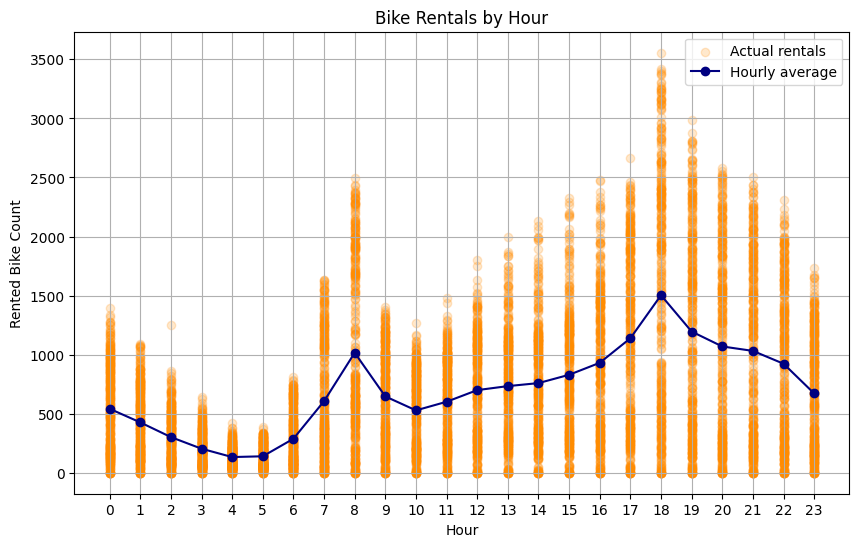

In [ ]:
# 시간대별 평균 대여량 계산
hourly_mean = bike_data.groupby('Hour')['Rented Bike Count'].mean()

# 그래프 그리기
plt.figure(figsize=(10, 6))

# 각 날짜·시간에 관측된 실제 대여량
plt.scatter(
    bike_data['Hour'],
    bike_data['Rented Bike Count'],
    color='darkorange',
    alpha=0.2,
    label='Actual rentals'
)

# 시간대별 평균 대여량
plt.plot(
    hourly_mean.index,
    hourly_mean.values,
    color='navy',
    marker='o',
    label='Hourly average'
)

plt.title('Bike Rentals by Hour')
plt.xlabel('Hour')
plt.ylabel('Rented Bike Count')
plt.xticks(range(24))
plt.legend()
plt.grid(True)
plt.show()

[선형회귀]
RMSE: 478.37
MAE: 358.03

[랜덤포레스트]
RMSE: 285.25
MAE: 171.09


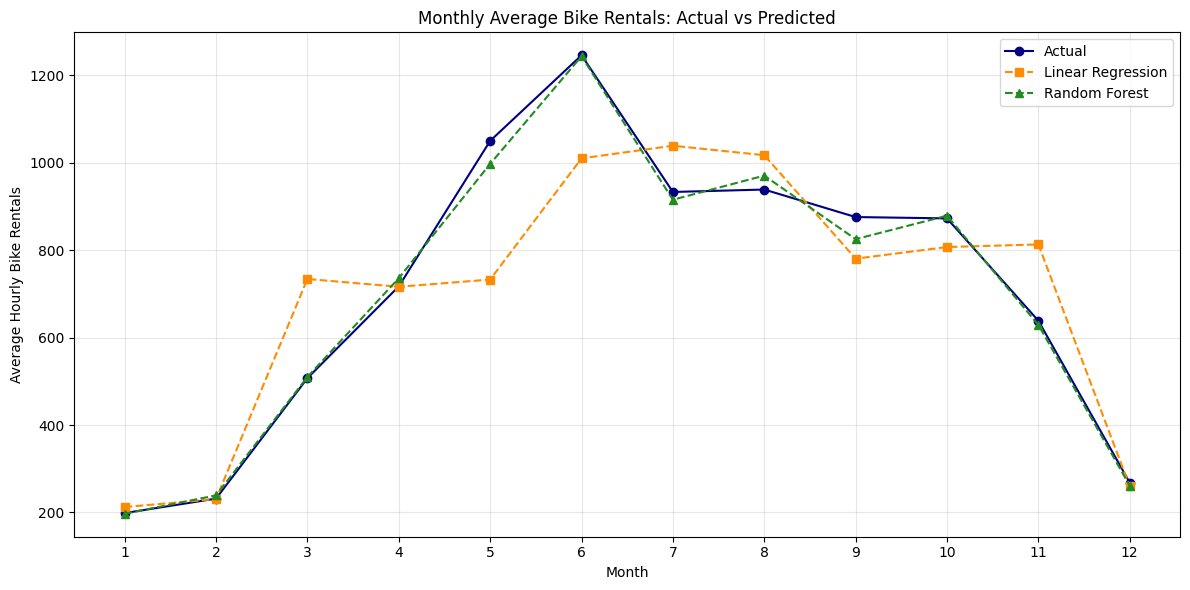

In [ ]:

# 학습·테스트 데이터 분리 및 모델 학습

# 원-핫 인코딩된 데이터 복사
bike_Rental = df_dummies.copy()

# 날짜에서 월 추출 (Date: 일/월/연도 형식)
bike_Rental['Month'] = pd.to_datetime(
    bike_Rental['Date'],
    format='%d/%m/%Y'
).dt.month

# 입력 X: 날짜와 정답을 제외한 나머지 컬럼
# 정답 y: 실제 자전거 대여량
X = bike_Rental.drop(columns=['Date', 'Rented Bike Count'])
y = bike_Rental['Rented Bike Count']

# 학습 데이터 80%, 테스트 데이터 20%로 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 선형회귀 모델 생성 및 학습
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 랜덤포레스트 모델 생성 및 학습
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)

# 테스트 데이터의 대여량 예측
y_pred_lr = lr_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)



# 예측 결과 평가 및 시각화

# 선형회귀 오차 계산
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)

# 랜덤포레스트 오차 계산
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)

# 평가 결과 출력
print("[선형회귀]")
print(f"RMSE: {rmse_lr:.2f}")
print(f"MAE: {mae_lr:.2f}")

print("\n[랜덤포레스트]")
print(f"RMSE: {rmse_rf:.2f}")
print(f"MAE: {mae_rf:.2f}")

# 같은 테스트 행의 월, 실제값, 예측값을 표로 구성
result_df = pd.DataFrame({
    'Month': X_test['Month'].values,
    'Actual': y_test.values,
    'LinearRegression': y_pred_lr,
    'RandomForest': y_pred_rf
})

# 월별 평균 계산
monthly_mean = result_df.groupby('Month').mean()

# 1월부터 12월 순서로 배치
monthly_mean = monthly_mean.reindex(range(1, 13))

# 월별 실제 대여량과 예측 대여량 비교 그래프
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_mean.index,
    monthly_mean['Actual'],
    color='navy',
    marker='o',
    label='Actual'
)

plt.plot(
    monthly_mean.index,
    monthly_mean['LinearRegression'],
    color='darkorange',
    marker='s',
    linestyle='--',
    label='Linear Regression'
)

plt.plot(
    monthly_mean.index,
    monthly_mean['RandomForest'],
    color='forestgreen',
    marker='^',
    linestyle='--',
    label='Random Forest'
)

plt.title('Monthly Average Bike Rentals: Actual vs Predicted')
plt.xlabel('Month')
plt.ylabel('Average Hourly Bike Rentals')
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()